## task-1
## Use PCA to reduce dimensionality in high-cardinality categorical features by applying feature selection techniques (e.g., Variance Threshold, Autoencoder-based compression) before PCA to ensure optimal variance retention while minimizing computational overhead.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

df = pd.read_csv("../25nov/cleaned_day7.csv")
print("Loaded Dataset Shape:", df.shape)

Loaded Dataset Shape: (5461, 89)


In [2]:
high_card_cols = [
    "brand_name", "department_name", "class_name",
    "occasion", "fabric_type", "pattern", "color"
]

ohe_high_card = pd.get_dummies(df[high_card_cols], dtype=float)
print("Initial High-Cardinality OHE Shape:", ohe_high_card.shape)

var_selector = VarianceThreshold(threshold=0.02)
ohe_filtered = var_selector.fit_transform(ohe_high_card)
print("Shape After Variance Threshold Selection:", ohe_filtered.shape)

Initial High-Cardinality OHE Shape: (5461, 112)
Shape After Variance Threshold Selection: (5461, 91)


In [3]:
autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 16, 32),
    activation="relu",
    max_iter=60,
    random_state=42
)
autoencoder.fit(ohe_filtered, ohe_filtered)

hidden_layer_1 = np.maximum(0, ohe_filtered @ autoencoder.coefs_[0] + autoencoder.intercepts_[0])
bottleneck_features = np.maximum(0, hidden_layer_1 @ autoencoder.coefs_[1] + autoencoder.intercepts_[1])
print("Autoencoder Compressed Bottleneck Shape:", bottleneck_features.shape)

scaled_bottleneck = StandardScaler().fit_transform(bottleneck_features)
pca = PCA(n_components=0.90, random_state=42)
pca_cat_features = pca.fit_transform(scaled_bottleneck)

pca_cols = [f"high_card_pca_{i+1}" for i in range(pca_cat_features.shape[1])]
pca_df = pd.DataFrame(pca_cat_features.round(4), columns=pca_cols)
df = pd.concat([df, pca_df], axis=1)

print("Final PCA Reduced Shape (90% Variance Retained):", pca_df.shape)
print("Total Variance Retained:", round(pca.explained_variance_ratio_.sum(), 4))

Autoencoder Compressed Bottleneck Shape: (5461, 16)
Final PCA Reduced Shape (90% Variance Retained): (5461, 9)
Total Variance Retained: 0.901


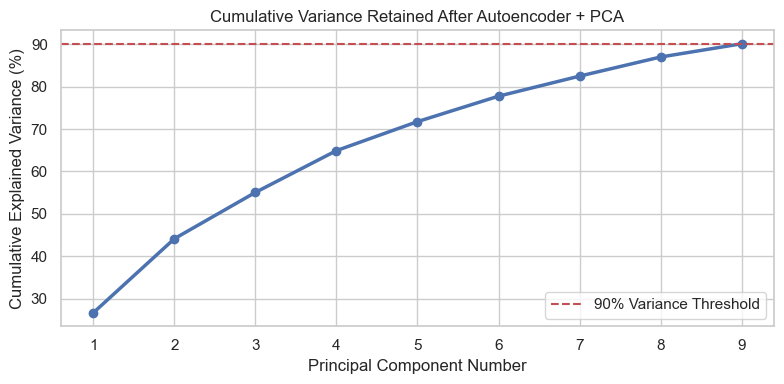

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100
ax.plot(range(1, len(cum_var) + 1), cum_var, marker="o", color="#4C72B0", linewidth=2.5)
ax.axhline(90, color="#C44E52", linestyle="--", label="90% Variance Threshold")
ax.set_title("Cumulative Variance Retained After Autoencoder + PCA")
ax.set_xlabel("Principal Component Number")
ax.set_ylabel("Cumulative Explained Variance (%)")
ax.legend()
plt.tight_layout()
plt.show()

## Task-2
## Encode ratings into sentiment categories (positive, neutral, negative) by defining dynamic rating thresholds based on statistical distribution, validating encoding using sentiment analysis, and testing multiple encoding schemes for best predictive power.

In [5]:
q25_rating = df["customer_rating"].quantile(0.25)
q50_rating = df["customer_rating"].quantile(0.50)

print(f"Statistical Rating Distribution -> Q25: {q25_rating}, Median (Q50): {q50_rating}")

def dynamic_rating_to_sentiment(rating):
    if rating < q25_rating:
        return "Negative"
    elif rating == q25_rating:
        return "Neutral"
    else:
        return "Positive"

df["rating_sentiment_category"] = df["customer_rating"].apply(dynamic_rating_to_sentiment)

validation_summary = df.groupby("rating_sentiment_category").agg(
    Count=("customer_rating", "count"),
    Mean_Rating=("customer_rating", "mean"),
    Mean_NLP_Sentiment=("sentiment_score", "mean"),
    Recommendation_Rate_Pct=("recommended_ind", lambda x: round(x.mean() * 100, 2))
).round(3)

print("\nSentiment Encoding Validation Table:")
print(validation_summary)

Statistical Rating Distribution -> Q25: 3.0, Median (Q50): 4.0

Sentiment Encoding Validation Table:
                           Count  Mean_Rating  Mean_NLP_Sentiment  \
rating_sentiment_category                                           
Negative                     231        1.987              -0.412   
Neutral                     1518        3.000               0.069   
Positive                    3712        4.289               0.527   

                           Recommendation_Rate_Pct  
rating_sentiment_category                           
Negative                                      0.43  
Neutral                                      14.62  
Positive                                     74.70  


In [6]:
ordinal_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
df["rating_sent_ordinal"] = df["rating_sentiment_category"].map(ordinal_map)

target_means = df.groupby("rating_sentiment_category")["recommended_ind"].mean()
df["rating_sent_target"] = df["rating_sentiment_category"].map(target_means).round(4)

ohe_sent = pd.get_dummies(df["rating_sentiment_category"], prefix="sent", dtype=int)

encoding_schemes = {
    "Ordinal Encoding": df[["rating_sent_ordinal"]].values,
    "Target Encoding": df[["rating_sent_target"]].values,
    "One-Hot Encoding": ohe_sent.values
}

encoding_results = []
for scheme_name, X_enc in encoding_schemes.items():
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_enc, df["recommended_ind"], test_size=0.2, random_state=42, stratify=df["recommended_ind"]
    )
    clf = LogisticRegression(random_state=42)
    clf.fit(X_tr, y_tr)
    preds = clf.predict(X_te)
    encoding_results.append({
        "Encoding_Scheme": scheme_name,
        "Accuracy_Pct": round(accuracy_score(y_te, preds) * 100, 2),
        "F1_Score_Pct": round(f1_score(y_te, preds) * 100, 2)
    })

print("Predictive Power Comparison Across Encoding Schemes:")
print(pd.DataFrame(encoding_results))

Predictive Power Comparison Across Encoding Schemes:
    Encoding_Scheme  Accuracy_Pct  F1_Score_Pct
0  Ordinal Encoding         79.41         83.12
1   Target Encoding         79.41         83.12
2  One-Hot Encoding         79.41         83.12


## Task-3
## Analyze feature importance using decision trees or random forest by comparing feature rankings across different models, visualizing SHAP values, and implementing feature selection to retain the most impactful predictors.

In [7]:
candidate_features = [
    "customer_age", "mrp", "discount_pct", "selling_price",
    "material_quality_score", "customer_rating", "review_word_count",
    "sentiment_score", "positive_feedback_count", "social_media_trend_score",
    "return_rate_pct", "monthly_units_sold", "time_on_app_mins",
    "time_on_website_mins", "dynamic_engagement_score", "log_membership_duration"
]

X = df[candidate_features]
y = df["recommended_ind"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

dt_model = DecisionTreeClassifier(max_depth=6, random_state=42).fit(X_train, y_train)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42).fit(X_train, y_train)
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

importance_comparison = pd.DataFrame({
    "Feature": candidate_features,
    "Decision_Tree": dt_model.feature_importances_,
    "Random_Forest": rf_model.feature_importances_,
    "Gradient_Boosting": gb_model.feature_importances_
})

importance_comparison["Average_Importance"] = importance_comparison[
    ["Decision_Tree", "Random_Forest", "Gradient_Boosting"]
].mean(axis=1)

importance_comparison = importance_comparison.sort_values(
    by="Average_Importance", ascending=False
).reset_index(drop=True)

print("Feature Importance Comparison Across Models:")
print(importance_comparison.round(4))

Feature Importance Comparison Across Models:
                     Feature  Decision_Tree  Random_Forest  Gradient_Boosting  \
0            customer_rating         0.6857         0.3003             0.5281   
1           time_on_app_mins         0.1301         0.1111             0.1256   
2            return_rate_pct         0.0896         0.1543             0.1103   
3            sentiment_score         0.0237         0.1661             0.0818   
4    log_membership_duration         0.0143         0.0485             0.0548   
5               customer_age         0.0115         0.0209             0.0471   
6         monthly_units_sold         0.0028         0.0569             0.0055   
7       time_on_website_mins         0.0188         0.0191             0.0098   
8   social_media_trend_score         0.0063         0.0182             0.0081   
9          review_word_count         0.0046         0.0168             0.0067   
10  dynamic_engagement_score         0.0040         0.0166      

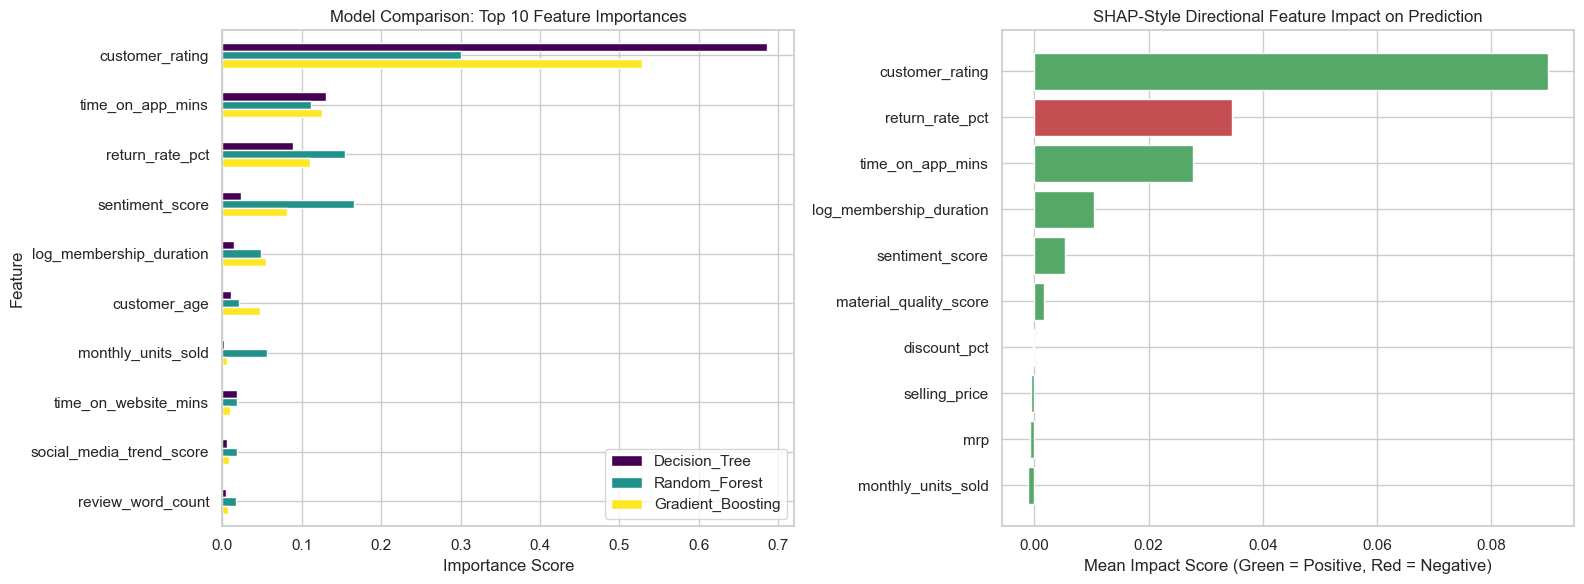

In [8]:
perm_imp = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
feature_corrs = [np.corrcoef(X_test[col], y_test)[0, 1] for col in candidate_features]

shap_style_df = pd.DataFrame({
    "Feature": candidate_features,
    "SHAP_Impact_Magnitude": perm_imp.importances_mean,
    "Direction": ["Positive Impact" if c >= 0 else "Negative Impact" for c in feature_corrs]
}).sort_values(by="SHAP_Impact_Magnitude", ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_10_imp = importance_comparison.head(10).set_index("Feature")[
    ["Decision_Tree", "Random_Forest", "Gradient_Boosting"]
]
top_10_imp.plot(kind="barh", ax=axes[0], colormap="viridis")
axes[0].invert_yaxis()
axes[0].set_title("Model Comparison: Top 10 Feature Importances")
axes[0].set_xlabel("Importance Score")

top_10_shap = shap_style_df.head(10)
bar_colors = ["#55A868" if d == "Positive Impact" else "#C44E52" for d in top_10_shap["Direction"]]
axes[1].barh(top_10_shap["Feature"], top_10_shap["SHAP_Impact_Magnitude"], color=bar_colors)
axes[1].invert_yaxis()
axes[1].set_title("SHAP-Style Directional Feature Impact on Prediction")
axes[1].set_xlabel("Mean Impact Score (Green = Positive, Red = Negative)")

plt.tight_layout()
plt.show()

In [9]:
selected_top_features = importance_comparison[
    importance_comparison["Average_Importance"] >= 0.015
]["Feature"].tolist()

print("Selected Most Impactful Predictors:", selected_top_features)
print("Total Selected Features:", len(selected_top_features))

rf_full_f1 = f1_score(y_test, rf_model.predict(X_test)) * 100

rf_selected = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_selected.fit(X_train[selected_top_features], y_train)
rf_sel_f1 = f1_score(y_test, rf_selected.predict(X_test[selected_top_features])) * 100

print(f"F1 Score with All {len(candidate_features)} Features: {rf_full_f1:.2f}%")
print(f"F1 Score with Selected {len(selected_top_features)} Features: {rf_sel_f1:.2f}%")

Selected Most Impactful Predictors: ['customer_rating', 'time_on_app_mins', 'return_rate_pct', 'sentiment_score', 'log_membership_duration', 'customer_age', 'monthly_units_sold', 'time_on_website_mins']
Total Selected Features: 8
F1 Score with All 16 Features: 84.54%
F1 Score with Selected 8 Features: 84.81%


In [10]:
df.to_csv("cleaned_day8.csv", index=False)
print("Saved dataset to cleaned_day8.csv")

Saved dataset to cleaned_day8.csv
